# Monte Carlo Simulation: Global Depolarizing Noise

Demonstrates `MonteCarloSimulator` and `Walkers` (Task 19).  
Three checks:
1. Noiseless MC matches `StatevectorSimulator` exactly  
2. Single-qubit global depolarizing: $\langle Z \rangle = 1 - 4p/3$ vs analytical  
3. Bell-state $\langle ZZ \rangle$ decay across multiple Trotter-style layers

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qaravan.core.circuit import Circuit
from qaravan.core.gates import H, CNOT, RX, RY, Z as ZGate
from qaravan.core.observables import PauliString
from qaravan.core.noise import DepolarizingNoise
from qaravan.backends.statevector import Statevector, StatevectorSimulator
from qaravan.backends.monte_carlo import MonteCarloSimulator, Walkers

## 1. Noiseless MC == StatevectorSimulator

With no noise model and `num_trajectories=1`, `MonteCarloSimulator` should give
exactly the same expectation values as `StatevectorSimulator`.

In [2]:
circ = Circuit([RX(0, 0.7), RY(1, 1.2), CNOT([0, 1]), RX(0, 0.4)], num_sites=2)
init = Statevector(bitstring="00")

sv = StatevectorSimulator(circ, init).run()
mc = MonteCarloSimulator(circ, init, num_trajectories=1, rng=np.random.default_rng(0))
walkers = mc.run()

observables = [PauliString("ZI"), PauliString("IZ"), PauliString("ZZ"), PauliString("XX")]
print(f"{'Observable':<12} {'SV':>10} {'MC (1 traj)':>14} {'diff':>10}")
print("-" * 48)
for obs in observables:
    sv_val = sv.expectation(obs).real
    mc_val = walkers.expectation(obs).real
    print(f"{obs.string:<12} {sv_val:>10.8f} {mc_val:>14.8f} {abs(sv_val-mc_val):>10.2e}")

Observable           SV    MC (1 traj)       diff
------------------------------------------------
ZI           -0.35908008    -0.35908008   0.00e+00
IZ           -0.12533270    -0.12533270   0.00e+00
ZZ           -0.51374715    -0.51374715   0.00e+00
XX           0.00000000     0.00000000   0.00e+00


**Expected:** diff column should be ~1e-15 (machine epsilon), confirming the MC path is
identical to the SV path when noise is absent.

## 2. $\langle Z \rangle$ vs error rate — single qubit global depolarizing

For a single qubit starting in $|0\rangle$, one application of global depolarizing
with error rate $p$ gives:

$$\mathcal{E}(|0\rangle\langle 0|) = \begin{pmatrix}1-2p/3 & 0 \\ 0 & 2p/3\end{pmatrix}
\implies \langle Z \rangle = 1 - \frac{4p}{3}$$

We use `Z(0)` as a dummy circuit layer (Z$|0\rangle = |0\rangle$) so that `_insert_noise`
fires exactly once.

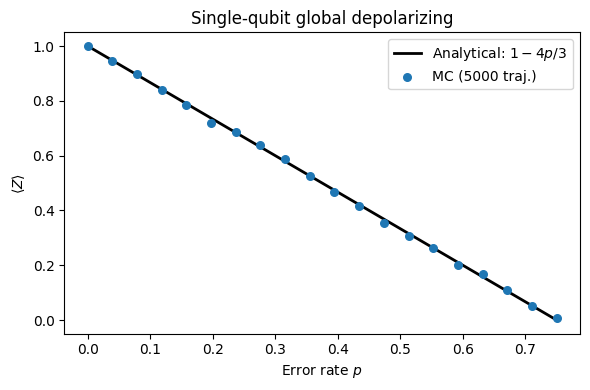

Max deviation from analytical: 0.0160  (expect < 0.03 at N=5000)


In [3]:
p_values = np.linspace(0, 0.75, 20)
analytical = 1 - 4 * p_values / 3

n_traj = 5000
mc_z = []
circ_1q = Circuit([ZGate(0)], num_sites=1)  # Z|0⟩ = |0⟩; one layer, no state change
init_1q = Statevector(bitstring="0")
obs_z = PauliString("Z")

for p in p_values:
    noise = DepolarizingNoise(num_sites=1, error_rate=float(p))
    mc = MonteCarloSimulator(
        circ_1q, init_1q, noise_model=noise,
        num_trajectories=n_traj, rng=np.random.default_rng(0)
    )
    mc_z.append(mc.run().expectation(obs_z).real)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(p_values, analytical, "k-", label=r"Analytical: $1 - 4p/3$", lw=2)
ax.scatter(p_values, mc_z, s=30, color="C0", zorder=5, label=f"MC ({n_traj} traj.)")
ax.set_xlabel("Error rate $p$")
ax.set_ylabel(r"$\langle Z \rangle$")
ax.set_title("Single-qubit global depolarizing")
ax.legend()
plt.tight_layout()
plt.show()

max_dev = max(abs(mc - ana) for mc, ana in zip(mc_z, analytical))
print(f"Max deviation from analytical: {max_dev:.4f}  (expect < 0.03 at N={n_traj})")

## 3. $\langle ZZ \rangle$ decay on a Bell state across layers

Build a circuit with $d$ copies of a two-qubit brick `[H(0), CNOT(0,1)]` (acting as
identity on the Bell state after the first repetition) and add depolarizing noise after
each layer. $\langle ZZ \rangle$ should decay with depth.

⟨ZZ⟩ noiseless (Bell state): 1.000000  (expect 1.0)


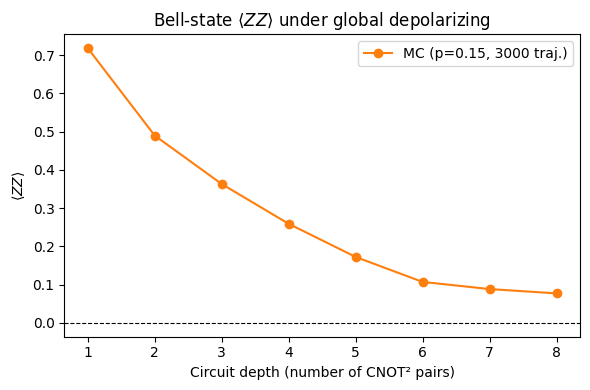

⟨ZZ⟩ values: ['0.719', '0.490', '0.363', '0.259', '0.173', '0.107', '0.089', '0.077']
Monotonically decreasing: True


In [4]:
# Build Bell state first
bell_prep = Circuit([H(0), CNOT([0, 1])], num_sites=2)
bell_sv = StatevectorSimulator(bell_prep, Statevector(bitstring="00")).run()
print(f"⟨ZZ⟩ noiseless (Bell state): {bell_sv.expectation(PauliString('ZZ')).real:.6f}  (expect 1.0)")

# Repeat an identity brick (CNOT then CNOT) to add layers without changing state
# CNOT^2 = I, so each repetition is a no-op on the state but adds circuit layers
obs_zz = PauliString("ZZ")
depths = list(range(1, 9))
p = 0.15
noise_2q = DepolarizingNoise(num_sites=2, error_rate=p)

zz_vs_depth = []
for d in depths:
    gates = []
    for _ in range(d):
        gates += [CNOT([0, 1]), CNOT([0, 1])]  # CNOT^2 = I, each is its own layer
    circ_d = Circuit(gates, num_sites=2)
    mc = MonteCarloSimulator(
        circ_d, bell_sv, noise_model=noise_2q,
        num_trajectories=3000, rng=np.random.default_rng(1)
    )
    zz_vs_depth.append(mc.run().expectation(obs_zz).real)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(depths, zz_vs_depth, "o-", color="C1", label=f"MC (p={p}, 3000 traj.)")
ax.axhline(0, color="k", lw=0.8, ls="--")
ax.set_xlabel("Circuit depth (number of CNOT² pairs)")
ax.set_ylabel(r"$\langle ZZ \rangle$")
ax.set_title("Bell-state $\\langle ZZ\\rangle$ under global depolarizing")
ax.legend()
plt.tight_layout()
plt.show()

print("⟨ZZ⟩ values:", [f"{v:.3f}" for v in zz_vs_depth])
print(f"Monotonically decreasing: {all(zz_vs_depth[i] >= zz_vs_depth[i+1] - 0.05 for i in range(len(zz_vs_depth)-1))}")

## Summary

| Check | Expected | Physics |
|---|---|---|
| Noiseless diff | ~1e-15 | MC path = SV path when no noise |
| $\langle Z\rangle$ vs $p$ | matches $1 - 4p/3$ | Global depolarizing analytical formula |
| $\langle ZZ\rangle$ decay | monotone decrease | Noise contracts state toward $I/4$ |

**What the tests do NOT verify here** (deferred to v0.2.3):  
Quantitative agreement between MC and `DensityMatrixSimulator` for multi-layer noisy
circuits — that cross-check is the acceptance criterion for Tasks 9/11.